<div style="text-align: right; font-size: 1.2em;">
Gaia Grossi, Leonardo Vanni<br>
Course project, Stochastic Processes, Bocconi University, January 2026
</div>

# <span style="color:#00008B;"> Project Proposal: Stochastic Dynamics of Viral Evolution </span>

## <span style="color:#00008B;"> 1 &nbsp; Introduction and Biological Motivation </span>

This project proposes to model the within-host evolutionary dynamics of a viral infection
(e.g., HIV or Influenza) subject to immune system pressure and pharmaceutical intervention.  

Viral infections are complex dynamic systems characterized by the interaction
between the virus, the host’s target cells, and the immune response. A critical challenge in
treating RNA viruses is their high mutation rate, which allows for the rapid emergence of drug-resistant strains.  

Our aim is to computationally model this within-host "arms race" to understand the critical factors that determine the course of the disease and the success of treatment.
<br><br>

The model is built around three core interacting agents:  
<span style="color:#00008B;">▶</span> &nbsp; ***The Virus:*** It tries to replicate by infecting host cells, and it can also mutate to become resistant to drugs.  
<span style="color:#00008B;">▶</span> &nbsp; ***The Drug Treatment:*** Medication is used to suppress the virus, either by blocking it from infecting new cells or by preventing it from replicating.  
<span style="color:#00008B;">▶</span> &nbsp; ***The Immune System:*** The host's own defense mechanism (specifically killer T-cells) actively finds and destroys infected cells.

<blockquote style="border-left: 4px solid #00008B; padding: 10px 15px; font-style: normal;">
The clinical outcome for a patient hinges on the interaction between these forces.  
Our goal is to investigate how drug efficacy, the viral mutation rate, and the strength of the immune response collectively determine whether the infection is cleared, settles into a chronic state, an acute state, or sees the emergence of a drug-resistant mutant.
</blockquote>

<br>

Classical epidemiology typically employs deterministic differential equations to model viral dynamics. However, because these models assume infinite population sizes and continuous variables, they fail to capture critical discrete phenomena.
<br>  

Specifically, they cannot account for stochastic extinction, where random fluctuations prevent a small initial viral inoculum from establishing an infection. Furthermore, they overlook evolutionary bottlenecks; while deterministic models allow fractions of a mutant virus to exist instantaneously, in reality, mutant populations are discrete and may drift to extinction despite having a fitness advantage.
<br>

To address these limitations, we employ two distinct but complementary simulation methods:  
<span style="color:#00008B;">▶</span> &nbsp; ***Deterministic Model (ODEs):***
   A set of mathematical equations that describe the average, continuous change in the populations of cells and viruses.  
   <span style="color:#00008B;">▶</span> &nbsp; ***Stochastic Model (Gillespie Algorithm):*** 
   A computer algorithm that simulates individual, random events.

<br>

## <span style="color:#00008B;"> 2 &nbsp; Mathematical Formulation of the Model </span>

### <span style="color:#00008B;"> 2.1 &nbsp; The State Space </span>

We define the state of the system at time $t$ as a discrete vector $\mathbf{X}(t) \in \mathbb{N}_0^6$:

$$
\mathbf{X}(t) = [T(t) \quad I_w(t) \quad I_m(t) \quad V_w(t) \quad V_m(t) \quad E(t)]^T
$$

where:  

- *$T$ &nbsp;:&nbsp;*  The population of uninfected target cells.
- *$I_w$ &nbsp;:&nbsp;*  The population of cells infected with the Wild-Type virus.
- *$I_m$ &nbsp;:&nbsp;*  The population of cells infected with the Mutant virus.
- *$V_w$ &nbsp;:&nbsp;*  The population of free Wild-Type viral particles.
- *$V_m$ &nbsp;:&nbsp;*  The population of free Mutant viral particles.
- *$E$ &nbsp;:&nbsp;*  The population of effector immune cells (CTLs).

### <span style="color:#00008B;"> 2.2 &nbsp; Reaction Channels and Stoichiometry </span>
The system evolves via $M = 15$ discrete reaction channels.  
For each reaction $j \in \{1, \dots, M\}$, we define a propensity function $a_j(\mathbf{X})$ and a state-change vector $\boldsymbol{\nu}_j$.
<br>

The reaction propensities depend on the following parameters:

- $\beta_w$, $\beta_m$: &nbsp;Infection rates of the wild-type and mutant virus, respectively.  
  They represent the probability per unit time that a free viral particle infects a susceptible target cell.

- $p_w$, $p_m$: &nbsp;Viral production rates of infected cells carrying the wild-type or mutant virus.  

- $\mu$: &nbsp;Mutation rate during viral production.

- $\lambda$: &nbsp;Production rate of uninfected target cells.

- $d_T$: &nbsp;Natural death rate of uninfected target cells.

- $c_w$, $c_m$: &nbsp;Clearance rates of free viral particles.

- $\delta$: &nbsp;Death rate of infected cells.

- $k$: &nbsp;Killing rate of infected cells by immune effector cells.

- $q$: &nbsp;Proliferation rate of immune effector cells.

- $d_E$: &nbsp;Natural death rate of immune effector cells.

<br>

<span style="color:#00008B;"> ***Viral Entry and Replication (with Mutation)*** </span>

We assume the wild-type is fit but susceptible to drugs, while the mutant is resistant but suffers a fitness cost (lower replication rate).

We simplify our model by assuming that the mutant exists already before the arrival of the drug. An interpretation of this assumption could be the existence of a variant of the virus unknown to the drug makers.

| $j$ | Event | Propensity $a_j(\mathbf{X})$ | State Change $(\boldsymbol{\nu}_j)$ |
| :--- | :--- | :--- | :--- |
| 1 | Infection by WT | $\beta_w T V_w$ | $T \to T-1, I_w \to I_w+1, V_w \to V_w-1$ |
| 2 | Infection by Mutant | $\beta_m T V_m$ | $T \to T-1, I_m \to I_m+1, V_m \to V_m-1$ |
| 3 | WT Production | $p_w(1-\mu)I_w$ | $V_w \to V_w+1$ |
| 4 | WT Mutation | $p_w \mu I_w$ | $V_m \to V_m+1$ |
| 5 | Mutant Production | $p_m I_m$ | $V_m \to V_m+1$ |

<br>

<span style="color:#00008B;"> ***Clearance and Death*** </span>

| $j$ | Event | Propensity $a_j(\mathbf{X})$ | State Change $(\boldsymbol{\nu}_j)$ |
| :--- | :--- | :--- | :--- |
| 6 | Target Production | $\lambda$ | $T \to T+1$ |
| 7 | Target Death | $d_T T$ | $T \to T-1$ |
| 8 | WT Clearance | $c_w V_w$ | $V_w \to V_w-1$ |
| 9 | Mutant Clearance | $c_m V_m$ | $V_m \to V_m-1$ |
| 10 | $I_w$ Lysis | $\delta I_w$ | $I_w \to I_w-1$ |
| 11 | $I_m$ Lysis | $\delta I_m$ | $I_m \to I_m-1$ |

<br>

<span style="color:#00008B;"> ***Immune Response*** </span>

We model the proliferation of immune cells proportional to the infection load, and their killing of infected cells.

| $j$ | Event | Propensity $a_j(\mathbf{X})$ | State Change $(\boldsymbol{\nu}_j)$ |
| :--- | :--- | :--- | :--- |
| 12 | CTL Killing WT | $k I_w E$ | $I_w \to I_w-1$ |
| 13 | CTL Killing Mut | $k I_m E$ | $I_m \to I_m-1$ |
| 14 | CTL Proliferation | $q(I_w + I_m)E$ | $E \to E+1$ |
| 15 | CTL Death | $d_E E$ | $E \to E-1$ |

<br>

### <span style="color:#00008B;"> 2.3 &nbsp; The Master Equation </span>

The probability $P(\mathbf{x}, t)$ of the system being in state $\mathbf{x}$ at time $t$ evolves according to the Master Equation:

$$
\frac{\partial P(\mathbf{x}, t)}{\partial t} = \sum_{j=1}^{15} [a_j(\mathbf{x} - \boldsymbol{\nu}_j) P(\mathbf{x} - \boldsymbol{\nu}_j, t) - a_j(\mathbf{x}) P(\mathbf{x}, t)] \tag{2}
$$

This equation is analytically intractable for high dimensions; therefore, we rely on Monte Carlo simulations.

A trajectory corresponding to a single Gillespie simulation represents an exact sample from the probability mass function that is the solution of the master equation. 

<br>

## <span style="color:#00008B;"> 3 &nbsp; Computational Implementation </span>

### <span style="color:#00008B;"> 3.1 &nbsp; Deterministic Simulation: ODEs </span>

The system of ODEs is derived from the stoichiometry:

$$
\begin{aligned}
(i) \quad \frac{dT}{dt} &= \lambda - d_T T - \beta_w T V_w - \beta_m T V_m, \\[6pt]
(ii) \quad \frac{dI_w}{dt} &= \beta_w T V_w - \delta I_w - k I_w E, \\[6pt]
(iii) \quad \frac{dI_m}{dt} &= \beta_m T V_m - \delta I_m - k I_m E, \\[6pt]
(iv) \quad \frac{dV_w}{dt} &= p_w(1 - \mu)I_w - c_w V_w - \beta_w T V_w, \\[6pt]
(v) \quad \frac{dV_m}{dt} &= p_w\mu I_w + p_m I_m - c_m V_m - \beta_m T V_m, \\[6pt]
(vi) \quad \frac{dE}{dt} &= q(I_w + I_m)E - d_E E.
\end{aligned}
$$

<br>

We establish a deterministic baseline for the viral infection.  
By solving these Ordinary Differential Equations (ODEs), we simulate the "average" behavior of the system as if the population sizes were infinite.  

<br>


### <span style="color:#00008B;">Deterministic simulations of chronic and acute infection</span>

In this section, we analyze the infection dynamics using a deterministic ODE model, which describes the average behavior of the system under the assumption of large populations. In this framework, the dynamics are fully determined by the model parameters and initial conditions, and the system evolves smoothly in time without random fluctuations.
    
Depending on the balance between viral replication, immune response, and clearance, the deterministic model predicts two qualitatively different infection outcomes: **chronic infection** and **acute infection**.

<blockquote style="border-left: 4px solid #00008B; padding-left: 20px; margin: 10px 0;">
  <div style="padding: 10px 0;">
    <p>
      In the <b>chronic infection</b> regime, the model predicts long-term persistence
      of the virus at a nonzero level. After an initial phase of rapid viral growth
      and immune activation, viral replication, immune-mediated killing, and cell
      turnover balance each other, leading to sustained infection. Biologically,
      this scenario corresponds to infections such as HIV, where the immune system
      and treatment reduce viral load but cannot eliminate the virus completely.
    </p>
      In contrast, in the <b>acute infection</b> regime, the model predicts rapid
      viral clearance and return to the disease-free state. Viral load may increase
      briefly following infection, but immune killing, clearance, and treatment
      dominate viral replication, causing viral populations to decline to zero.
      This behaviour is representative of acute infections such as influenza.
  </div>
</blockquote>


These deterministic simulations provide a clear baseline for understanding the possible long-term behaviors of the system. However, they do not account for random fluctuations that can be important when population sizes are small, particularly during the early stages of infection.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint, solve_ivp

np.random.seed(42)

#CHRONIC INFECTION PARAMETERS

params_chronic = {
    'lam': 1.0e4,    # lambda: Target cell production
    'dT': 0.01,       # d_T: Target cell death
    'bw': 2.0e-5,    # beta_w: WT infection rate
    'bm': 1.0e-5,    # beta_m: Mutant infection rate (lower fitness)
    # This makes the Wild-Type more infectious than the Mutant.
    # This models the biological reality that drug-resistant mutations often make the virus 
    # "weaker" or slower to replicate in a drug-free environment (Fitness Cost).
    'pw': 20.0,     # p_w: WT production
    'pm': 18.0,     # p_m: Mutant production
    'mu': 1.0e-4,    # mu: Mutation rate
    'cw': 4.0,       # c_w: WT clearance
    'cm': 4.0,       # c_m: Mutant clearance
    'delta': 0.5,    # delta: Infected cell lysis rate
    'k': 1.0e-4,       # k: CTL killing rate
    'q': 1.0e-4,       # q: CTL proliferation
    'dE': 0.1        # d_E: CTL death
}

# Initial State: [T, Iw, Im, Vw, Vm, E]
y0_chronic = np.array([1000, 0, 0, 10, 0, 10])

def ode_system(y, t, p):
    T, Iw, Im, Vw, Vm, E = np.maximum(y, 0)

    # Eq (i): dT/dt
    dTdt = p['lam'] - p['dT']*T - p['bw']*T*Vw - p['bm']*T*Vm
    
    # Eq (ii): dIw/dt
    dIwdt = p['bw']*T*Vw - p['delta']*Iw - p['k']*Iw*E
    
    # Eq (iii): dIm/dt
    dImdt = p['bm']*T*Vm - p['delta']*Im - p['k']*Im*E
    
    # Eq (iv): dVw/dt
    dVwdt = p['pw']*(1 - p['mu'])*Iw - p['cw']*Vw - p['bw']*T*Vw
    
    # Eq (v): dVm/dt
    dVmdt = p['pw']*p['mu']*Iw + p['pm']*Im - p['cm']*Vm - p['bm']*T*Vm
    
    # Eq (vi): dE/dt
    dEdt = p['q']*(Iw + Im)*E - p['dE']*E
    
    return [dTdt, dIwdt, dImdt, dVwdt, dVmdt, dEdt]

def solve_deterministic(params, t_max, y0):
    t_span = (0, t_max)
    sol = solve_ivp(
        fun=lambda t, y: ode_system(y, t, params),
        t_span=t_span,
        y0=y0,
        method='LSODA',
        rtol=1e-6,
        atol=1e-9
    )
    
    return sol

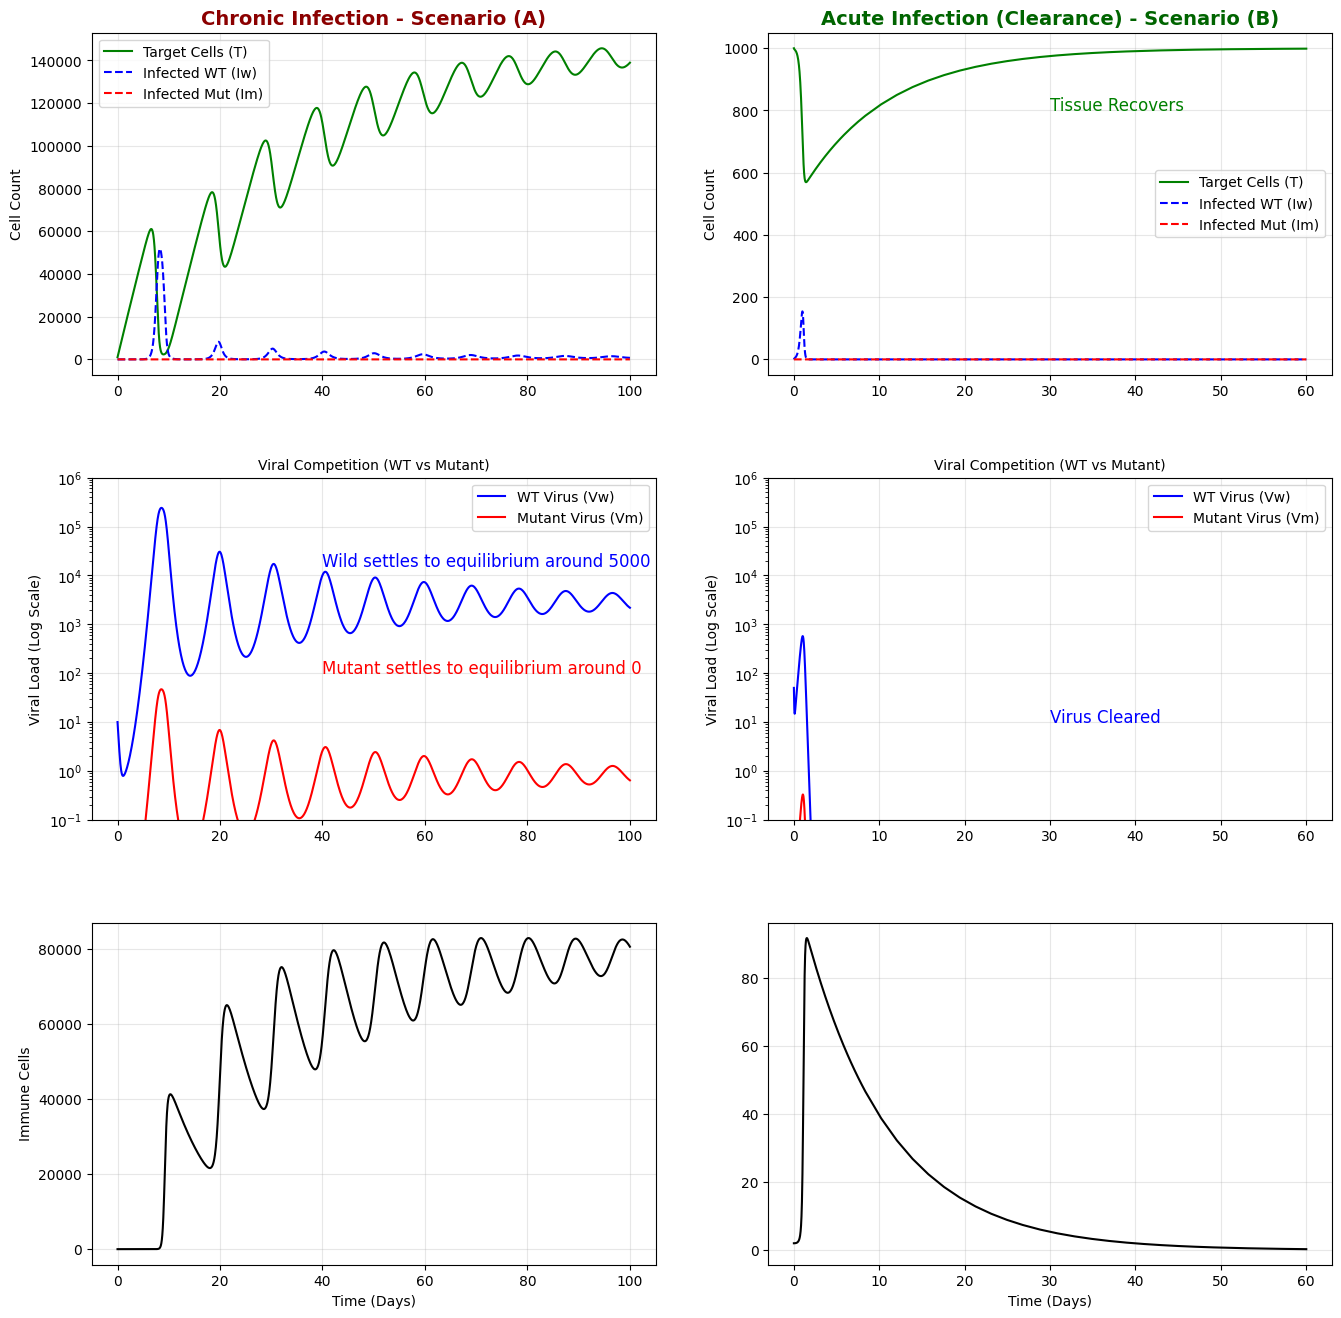

In [2]:
#ACUTE INFECTION PARAMETERS

params_acute = {
    'lam': 100.0,
    'dT': 0.1,
    'bw': 0.002,
    'bm': 0.002,        
    'pw': 100.0,
    'pm': 100.0,
    'mu': 1e-4,  
    'cw': 25.0,
    'cm': 25.0,
    'delta': 1,       
    'q': 0.05,           
    'k': 0.2,           
    'dE': 0.1          
}

y0_acute = [1000, 0, 0, 50, 0, 2]  
t_eval = np.linspace(0, 60, 2000)

sol_chronic = solve_deterministic(params_chronic, 100, y0_chronic)
sol_acute = solve_deterministic(params_acute, 60, y0_acute)

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
plt.subplots_adjust(hspace=0.3)

axes[0,0].set_title("Chronic Infection - Scenario (A)", fontsize=14, color='darkred', fontweight='bold')
axes[0,1].set_title("Acute Infection (Clearance) - Scenario (B)", fontsize=14, color='darkgreen', fontweight='bold')

# --- CHRONIC (Left) ---
axes[0,0].plot(sol_chronic.t, sol_chronic.y[0], 'g-', label='Target Cells (T)')
axes[0,0].plot(sol_chronic.t, sol_chronic.y[1], 'b--', label='Infected WT (Iw)')
axes[0,0].plot(sol_chronic.t, sol_chronic.y[2], 'r--', label='Infected Mut (Im)')
axes[0,0].set_ylabel('Cell Count')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

axes[1,0].plot(sol_chronic.t, sol_chronic.y[3], 'b-', label='WT Virus (Vw)')
axes[1,0].plot(sol_chronic.t, sol_chronic.y[4], 'r-', label='Mutant Virus (Vm)')
axes[1,0].set_yscale('log')
axes[1,0].set_ylim(1e-1, 1e6)
axes[1,0].set_ylabel('Viral Load (Log Scale)')
axes[1,0].set_title('Viral Competition (WT vs Mutant)', fontsize=10)
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)
axes[1,0].text(40, 100, "Mutant settles to equilibrium around 0", fontsize=12, color='red')
axes[1,0].text(40, 15000, "Wild settles to equilibrium around 5000", fontsize=12, color='blue')

axes[2,0].plot(sol_chronic.t, sol_chronic.y[5], 'k-')
axes[2,0].set_ylabel('Immune Cells')
axes[2,0].set_xlabel('Time (Days)')
axes[2,0].grid(alpha=0.3)

# --- ACUTE (Right) ---
axes[0,1].plot(sol_acute.t, sol_acute.y[0], 'g-', label='Target Cells (T)')
axes[0,1].plot(sol_acute.t, sol_acute.y[1], 'b--', label='Infected WT (Iw)')
axes[0,1].plot(sol_acute.t, sol_acute.y[2], 'r--', label='Infected Mut (Im)')
axes[0,1].set_ylabel('Cell Count')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)
axes[0,1].text(30, 800, "Tissue Recovers", fontsize=12, color='green')

axes[1,1].plot(sol_acute.t, sol_acute.y[3], 'b-', label='WT Virus (Vw)')
axes[1,1].plot(sol_acute.t, sol_acute.y[4], 'r-', label='Mutant Virus (Vm)')
axes[1,1].set_yscale('log')
axes[1,1].set_ylim(1e-1, 1e6)
axes[1,1].set_ylabel('Viral Load (Log Scale)')
axes[1,1].set_title('Viral Competition (WT vs Mutant)', fontsize=10)
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)
axes[1,1].text(30, 10, "Virus Cleared", fontsize=12, color='blue')

axes[2,1].plot(sol_acute.t, sol_acute.y[5], 'k-')
axes[2,1].set_xlabel('Time (Days)')
axes[2,1].grid(alpha=0.3)

plt.show()

<br> 

***Scenario (A): Establishment of Chronic Infection***  

The simulation results show the emergence of a chronic infection characterized by **persistent damped oscillations**. Initially, the wild-type virus (blue curve) replicates rapidly, causing a sharp decline in the population of target cells (green curve).

This rapid viral expansion triggers a strong immune response (black curve), which significantly suppresses the viral load but fails to eliminate it completely. As immune pressure temporarily reduces viral replication, the virus rebounds, leading to repeated waves of infection.

Over time, the amplitude of these oscillations decreases, indicating convergence toward a **stable endemic equilibrium** (a stable spiral sink). At this equilibrium, viral load, target cells, and immune effectors coexist at steady, nonzero levels.
<br><br>

***Scenario (B): Establishment of Chronic Infection***  

The simulation results show a brief initial increase in viral load, followed by a rapid decline as effector immune cells expand and efficiently eliminate infected cells. Both wild-type and mutant viral populations decay to zero, and infected cell populations vanish.

Once the infection is cleared, immune effector cells decline due to the absence of the virus, and the system approaches the **disease-free equilibrium**. Target cells recover to their normal steady level, determined by the balance between production and natural death.

Although the deterministic model predicts certain clearance in this regime, it does not capture the role of random fluctuations during the early stages of infection. In particular, stochastic effects can lead to viral extinction even in parameter regimes that would allow growth on average, motivating the stochastic analysis developed in the next section.

<br>

### <span style="color:#00008B;"> 3.2 &nbsp; Stochastic Simulation: Gillespie Algorithm </span>  

In the previous section, we analyzed the infection dynamics using a deterministic ODE model, which describes the *average* behavior of large populations. While this approach is useful for understanding long-term trends, it does not account for randomness in systems where population sizes are small, especially during the early stages of infection.

To address this limitation, we now use a **stochastic simulation framework** based on the **Gillespie algorithm**. This method explicitly models individual reaction events (such as infection, viral production, and clearance) as random processes. As a result, identical initial conditions can lead to different outcomes in different simulation runs.

Stochastic simulations are particularly important when the infection starts from a very small number of viral particles, where chance events can determine whether the virus successfully establishes or goes extinct.

<br>

### <span style="color:#00008B;">Stochastic simulations of chronic and acute infection</span>

As in the deterministic case, we consider two qualitatively different infection outcomes:

- **Chronic infection**, where the virus persists over long times,
- **Acute infection**, where the virus is rapidly cleared.

Using the Gillespie algorithm, these outcomes are no longer guaranteed. Even in parameter regimes where the deterministic model predicts chronic infection, stochastic effects can lead to early viral extinction. Conversely, successful establishment occurs only in a fraction of simulation runs.

This highlights a key difference between deterministic and stochastic descriptions:  
the deterministic model predicts what happens *on average*, while the stochastic model reveals the *probability* of different outcomes.


Running Stochastic (Gillespie)...
  -> Realization 1: Infection survived!


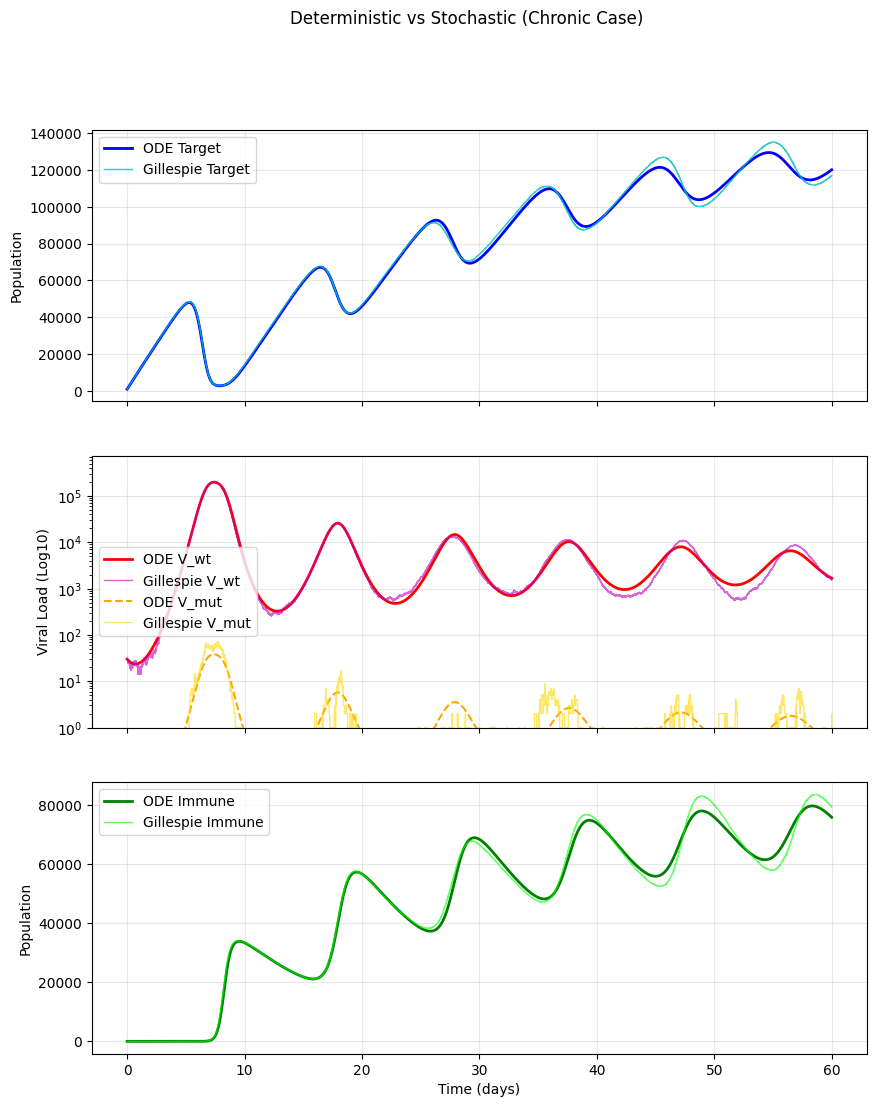

In [3]:
import warnings

warnings.filterwarnings("ignore", message="Creating legend with loc=\"best\"")

y0_chronic = np.array([1e3, 5, 0, 30, 0, 10]) 
params_chronic = {
    'lam': 1e4,      
    'dT': 0.01,            
    'bw': 2e-5,
    'bm': 1e-5,
    'pw': 20.0,
    'pm': 18.0,
    'mu': 1e-4,           
    'cw': 4.0,
    'cm': 4.0,
    'delta': 0.5,           
    'k': 1e-4,
    'q': 1e-4,
    'dE': 0.1              
}

solution_ode_chronic = solve_deterministic(params_chronic, 60, y0_chronic)

IDX = {
    'T': 0,
    'Iw': 1,
    'Im': 2, 
    'Vw': 3,
    'Vm': 4, 
    'E': 5 
}

NUM_SPECIES = 6
NUM_REACTIONS = 15

def get_stoichiometry_matrix():

    S = np.zeros((NUM_SPECIES, NUM_REACTIONS), dtype=int)
    
    S[IDX['T'], 0]  = -1
    S[IDX['Iw'], 0] = +1
    S[IDX['Vw'], 0] = -1
    
    S[IDX['T'], 1]  = -1
    S[IDX['Im'], 1] = +1
    S[IDX['Vm'], 1] = -1
    
    S[IDX['Vw'], 2] = +1
    
    S[IDX['Vm'], 3] = +1
    
    S[IDX['Vm'], 4] = +1
    
    S[IDX['T'], 5] = +1
    
    S[IDX['T'], 6] = -1
    
    S[IDX['Vw'], 7] = -1
    
    S[IDX['Vm'], 8] = -1
    
    S[IDX['Iw'], 9] = -1
    
    S[IDX['Im'], 10] = -1
    
    S[IDX['Iw'], 11] = -1
    
    S[IDX['Im'], 12] = -1
    
    S[IDX['E'], 13] = +1
    
    S[IDX['E'], 14] = -1
    
    return S

def gillespie_ssa(params, t_max, initial_state):
    t = 0.0
    state = initial_state.copy().astype(int)
    
    time_history = [t]
    state_history = [state.copy()]
    
    lam = params['lam']
    d_T = params['dT']
    beta_w = params['bw']
    beta_m = params['bm']
    p_w = params['pw']
    p_m = params['pm']
    mu = params['mu']
    c_w = params['cw']
    c_m = params['cm']
    delta = params['delta']
    k = params['k']
    q = params['q']
    d_E = params['dE']
    
    S = get_stoichiometry_matrix()
    
    while t < t_max:
        
        T, Iw, Im, Vw, Vm, E = state
        
        a = np.zeros(15)
        
        a[0] = beta_w * T * Vw          # Infection WT
        a[1] = beta_m * T * Vm          # Infection Mut
        
        a[2] = p_w * (1 - mu) * Iw      # WT Production
        a[3] = p_w * mu * Iw            # Mutation
        a[4] = p_m * Im                 # Mut Production
        
        a[5] = lam                      # Target Prod
        a[6] = d_T * T                  # Target Death
        
        a[7] = c_w * Vw                 # WT Clearance
        a[8] = c_m * Vm                 # Mut Clearance
        
        a[9] = delta * Iw               # WT Lysis
        a[10] = delta * Im              # Mut Lysis
        
        a[11] = k * Iw * E              # Kill WT
        a[12] = k * Im * E              # Kill Mut
        
        a[13] = q * (Iw + Im) * E       # Immune Prolif
        a[14] = d_E * E                 # Immune Death
        
        a0 = np.sum(a)
        
        if a0 == 0:
            time_history.append(t_max)
            state_history.append(state)
            break
            
        tau = np.random.exponential(1/a0)
        
        if t + tau > t_max:
            time_history.append(t_max)
            state_history.append(state)
            break
            
        t += tau
        
        r = np.random.uniform(0, a0)
        cumulative_a = np.cumsum(a)
        reaction_idx = np.searchsorted(cumulative_a, r)
        
        state = state + S[:, reaction_idx]
        
        time_history.append(t)
        state_history.append(state.copy())

    return np.array(time_history), np.array(state_history)


print("Running Stochastic (Gillespie)...")

max_attempts = 1
t_stoch, y_stoch = None, None

for i in range(max_attempts):
    ts, ys = gillespie_ssa(params_chronic, 60, y0_chronic)
    if ys[-1, IDX['Vw']] > 0: 
        print(f"  -> Realization {i+1}: Infection survived!")
        t_stoch, y_stoch = ts, ys
        break
    else:
        print(f"  -> Realization {i+1}: Virus went extinct.")

if t_stoch is None:
    print("Virus died in all attempts. The immune system/clearance is very strong.")
    t_stoch, y_stoch = ts, ys

fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

ax[0].plot(solution_ode_chronic.t, solution_ode_chronic.y[IDX['T']], 'b-', label='ODE Target', linewidth=2)
ax[0].step(t_stoch, y_stoch[:, IDX['T']], 'c-', alpha=0.8, linewidth=1, label='Gillespie Target')
ax[0].set_ylabel('Population')
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(solution_ode_chronic.t, solution_ode_chronic.y[IDX['Vw']], 'r-', label='ODE V_wt', linewidth=2)
ax[1].step(t_stoch, y_stoch[:, IDX['Vw']], 'm-', alpha=0.6, linewidth=1, label='Gillespie V_wt')
ax[1].plot(solution_ode_chronic.t, solution_ode_chronic.y[IDX['Vm']], 'orange', linestyle='--', label='ODE V_mut')
ax[1].step(t_stoch, y_stoch[:, IDX['Vm']], 'gold', alpha=0.6, linewidth=1, label='Gillespie V_mut')

ax[1].set_ylabel('Viral Load (Log10)')
ax[1].set_yscale('log')
ax[1].set_ylim(bottom=1) 
ax[1].legend()
ax[1].grid(alpha=0.3)

ax[2].plot(solution_ode_chronic.t, solution_ode_chronic.y[IDX['E']], 'g-', label='ODE Immune', linewidth=2)
ax[2].step(t_stoch, y_stoch[:, IDX['E']], 'lime', alpha=0.6, linewidth=1, label='Gillespie Immune')
ax[2].set_ylabel('Population')
ax[2].set_xlabel('Time (days)')
ax[2].legend()
ax[2].grid(alpha=0.3)

plt.suptitle('Deterministic vs Stochastic (Chronic Case)')
plt.show()


***Chronic Infection Results:***  
The stochastic simulations reproduce the qualitative behaviour predicted by the deterministic ODE model in the chronic infection regime. In particular, both approaches show sustained oscillations in viral load, immune response, and target cell populations, indicating long-term viral persistence.

The wild-type viral load exhibits repeated peaks followed by partial suppression due to immune activity. While the deterministic solution produces smooth, regular oscillations, the stochastic trajectories display noticeable fluctuations around the ODE prediction. These fluctuations arise from the random timing of individual infection, replication, and clearance events.

Despite this variability, the stochastic trajectories closely track the deterministic mean over time, especially once population sizes become large. This confirms that the ODE model provides an accurate description of the *average* dynamics in the chronic regime, while the Gillespie simulations capture the variability around this mean.

The immune population shows a similar pattern: an initial rapid expansion followed by oscillatory behavior that gradually stabilizes. Overall, these results indicate that once the infection is established, stochastic effects mainly introduce fluctuations but do not qualitatively change the chronic outcome predicted by the deterministic model.

<br> <br>


Running Stochastic (Gillespie)...
  -> Spike found on attempt 1


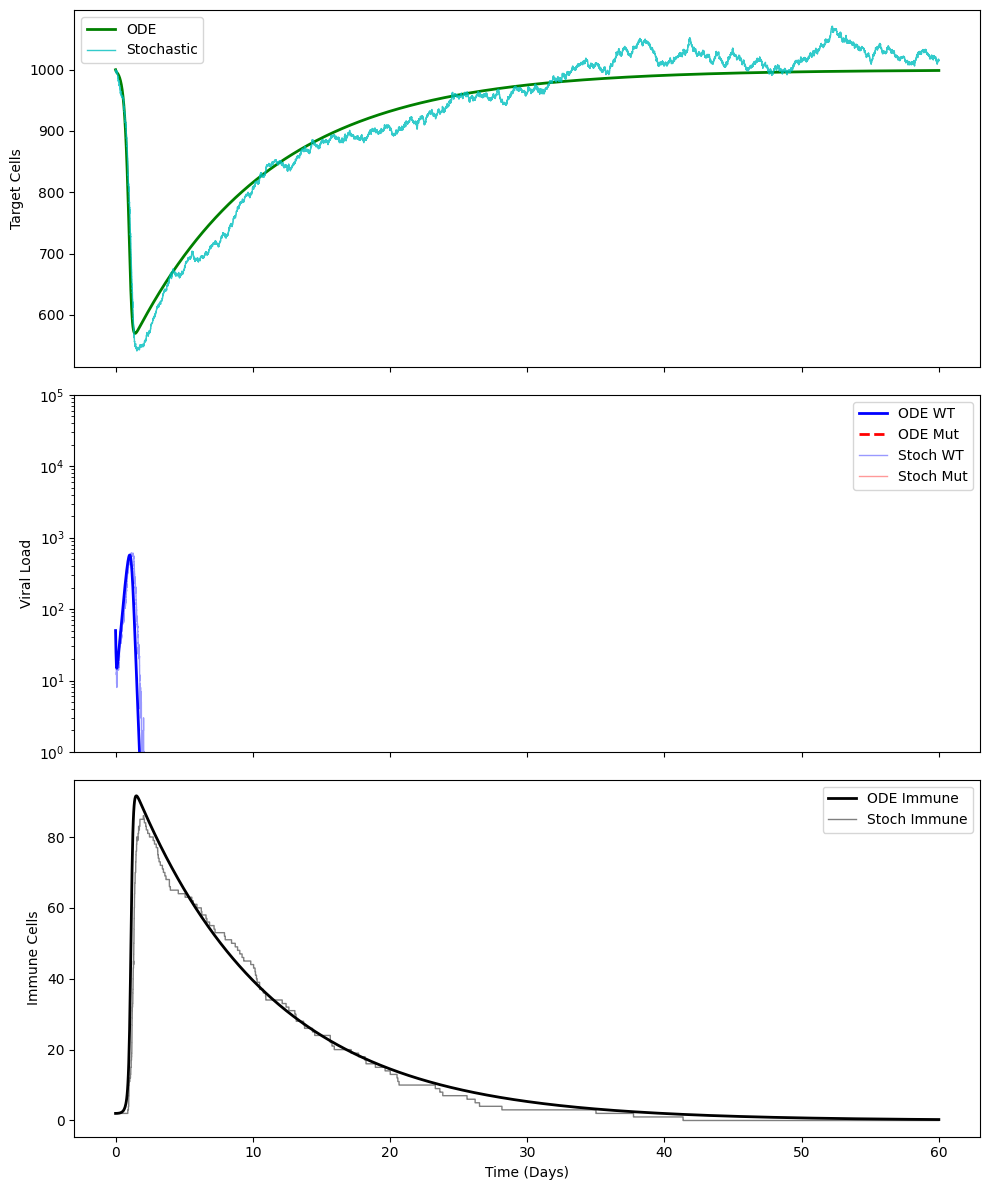

In [4]:
y0_acute = np.array([1000, 0, 0, 50, 0, 2]) 

params_acute = {
    'lam': 100.0, 'dT': 0.1,    
    'bw': 0.002, 'bm': 0.002,
    'pw': 100.0, 'pm': 100.0,
    'mu': 1e-4,  
    'cw': 25.0,  'cm': 25.0,
    'delta': 1.0,       
    'q': 0.05, 'k': 0.2, 'dE': 0.1
}

t_eval = np.linspace(0, 60, 2000)
sol_ode = odeint(ode_system, y0_acute, t_eval, args=(params_acute,))

print("Running Stochastic (Gillespie)...")
t_stoch, y_stoch = None, None
for i in range(10):
    ts, ys = gillespie_ssa(params_acute, 60, y0_acute)
    if np.max(ys[:, 3]) > 200:
        t_stoch, y_stoch = ts, ys
        print(f"  -> Spike found on attempt {i+1}")
        break

if t_stoch is None: t_stoch, y_stoch = ts, ys

fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
IDX = {'T': 0, 'Iw': 1, 'Im': 2, 'Vw': 3, 'Vm': 4, 'E': 5}

ax[0].plot(t_eval, sol_ode[:, 0], 'g-', lw=2, label='ODE')
ax[0].step(t_stoch, y_stoch[:, 0], 'c-', lw=1, alpha=0.8, label='Stochastic')
ax[0].set_ylabel('Target Cells')
ax[0].legend()

ax[1].plot(t_eval, sol_ode[:, 3], 'b-', lw=2, label='ODE WT')
ax[1].plot(t_eval, sol_ode[:, 4], 'r--', lw=2, label='ODE Mut')
ax[1].step(t_stoch, y_stoch[:, 3], 'b-', lw=1, alpha=0.4, label='Stoch WT')
ax[1].step(t_stoch, y_stoch[:, 4], 'r-', lw=1, alpha=0.4, label='Stoch Mut')
ax[1].set_yscale('log')
ax[1].set_ylim(1e0, 1e5)
ax[1].set_ylabel('Viral Load')
ax[1].legend()

ax[2].plot(t_eval, sol_ode[:, 5], 'k-', lw=2, label='ODE Immune')
ax[2].step(t_stoch, y_stoch[:, 5], 'k-', lw=1, alpha=0.5, label='Stoch Immune')
ax[2].set_ylabel('Immune Cells')
ax[2].set_xlabel('Time (Days)')
ax[2].legend()

plt.tight_layout()
plt.show()

***Acute Infection Results:***  
In the acute infection regime, both deterministic and stochastic simulations predict rapid viral clearance. The viral population rises briefly after infection but quickly collapses to zero as immune cells expand and eliminate infected cells.

The deterministic model predicts a smooth decline in viral load and immune contraction after clearance. In contrast, the stochastic simulation shows a more irregular trajectory, with random fluctuations during the early phase of infection when population sizes are small.

Importantly, the stochastic simulation confirms viral extinction, even though short-lived viral spikes may occur. After clearance, immune cells gradually decrease over time, and target cells recover toward their normal level.

In this case, stochastic effects do not prevent clearance but introduce variability in the timing and shape of the dynamics.

<br> <br>

### <span style="color:#00008B;">Phase–Space Analysis: Virus–Immune Dynamics</span>

After characterizing chronic and acute infection outcomes in time, we further analyze the system by examining its behavior in phase space. In particular, we study the joint dynamics of viral load and immune response by plotting trajectories in the $(V_w, E)$ plane.

This analysis is performed using parameter values corresponding to the **chronic infection regime**, for which the deterministic model admits a stable nonzero equilibrium. We compare a single stochastic trajectory generated using the Gillespie algorithm with the deterministic solution of the ODE model, starting from the same initial condition. This allows us to visualize how stochastic fluctuations evolve around the deterministic fixed point associated with chronic infection.

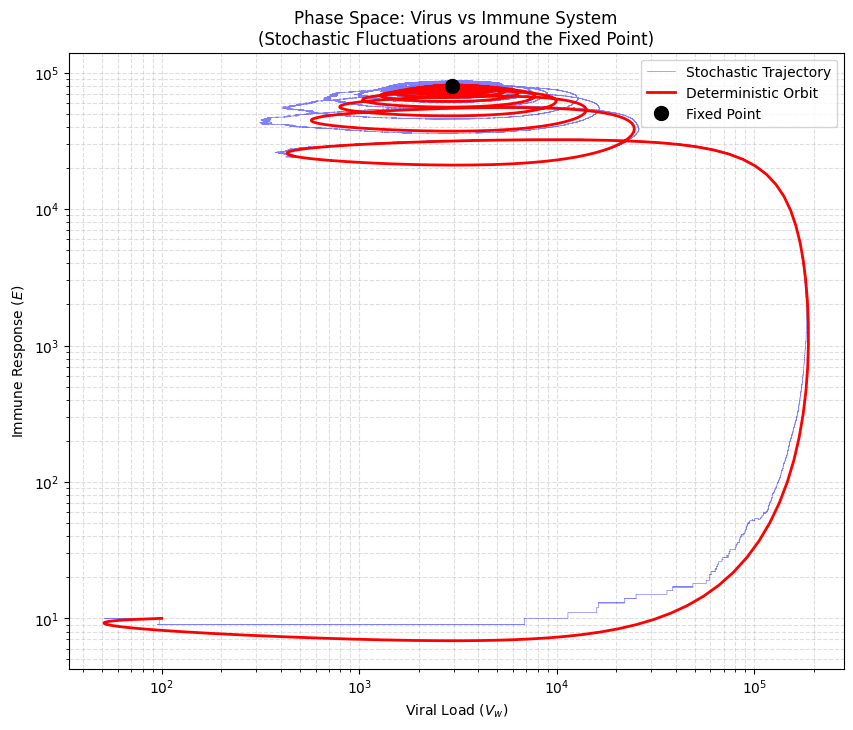

In [5]:
y0_phase = np.array([1000, 10, 0, 100, 0, 10]) 
t_stoch, y_stoch = gillespie_ssa(params_chronic, 200, y0_phase)

t_eval = np.linspace(0, 200, 2000)
sol_ode = odeint(ode_system, y0_phase, t_eval, args=(params_chronic,))

plt.figure(figsize=(10, 8))

plt.plot(y_stoch[:, 3], y_stoch[:, 5], 'b-', alpha=0.5, linewidth=0.5, label='Stochastic Trajectory')

plt.plot(sol_ode[:, 3], sol_ode[:, 5], 'r-', linewidth=2, label='Deterministic Orbit')

plt.plot(sol_ode[-1, 3], sol_ode[-1, 5], 'ko', markersize=10, label='Fixed Point') 
# NOTE: approximated to the end of the deterministic simulation since t is "large enough"

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Viral Load ($V_w$)')
plt.ylabel('Immune Response ($E$)')
plt.title('Phase Space: Virus vs Immune System\n(Stochastic Fluctuations around the Fixed Point)')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.show()

The phase–space plot shows that the deterministic trajectory (red) spirals toward a stable fixed point, corresponding to a chronic infection equilibrium where viral load and immune response coexist at constant levels. 

The stochastic trajectory (blue) fluctuates around this deterministic orbit, reflecting random variability due to discrete infection and clearance events. Despite these fluctuations, the stochastic dynamics remain confined near the fixed point, indicating that the chronic equilibrium is stable and robust to noise.

<br> <br> 

### <span style="color:#00008B;">Probability of Infection Establishment</span>

We estimate the probability that an infection becomes established when starting from a single wild-type viral particle ($V_0 = 1$). Using the Gillespie algorithm, we run 1000 independent stochastic simulations with identical parameters and initial conditions.

Each simulation is classified as **established** if the viral population is still present after 30 days, and **extinct** otherwise. This approach allows us to quantify how random fluctuations during the early stages of infection affect the likelihood of successful viral growth, even in parameter regimes where the deterministic model predicts infection establishment.

Running 1000 simulations (V0=1)...

RESULTS FOR V0=1 (80% FITNESS RATIO)
Stochastic Results:
  - Extinct:      951 times (95.1%)
  - Established:  49 times (4.9%)


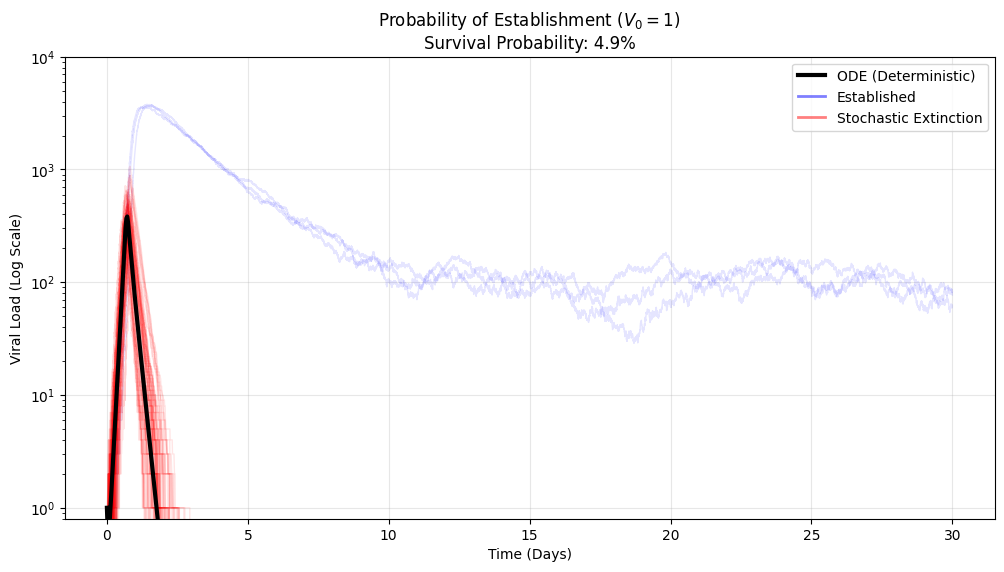

In [6]:
params = {
    'lam': 10.0,
    'dT': 0.01,
    'bw': 0.02,   'bm': 0.016,
    'pw': 20.0,   'pm': 20.0,
    'mu': 1.0e-4,
    'cw': 4.0,    'cm': 4.0,
    'delta': 0.5,
    'k': 0.1,     'q': 0.1,
    'dE': 0.1
}

y0_experiment = [1000, 0, 0, 1, 0, 1]

N_TRIALS = 1000
T_CHECK = 30

success_count = 0
extinction_count = 0

all_times = []
all_viral_loads = []

print(f"Running {N_TRIALS} simulations (V0=1)...")

for i in range(N_TRIALS):
    y0_arr = np.array(y0_experiment)
    ts, ys = gillespie_ssa(params, T_CHECK, y0_arr)

    if i < 100:
        all_times.append(ts)
        all_viral_loads.append(ys[:, 3] + ys[:, 4])

    if ys[-1, 3] + ys[-1, 4] > 0:
        success_count += 1
    else:
        extinction_count += 1

prob_survival = (success_count / N_TRIALS) * 100
prob_extinction = (extinction_count / N_TRIALS) * 100

print("\n" + "="*40)
print("RESULTS FOR V0=1 (80% FITNESS RATIO)")
print("="*40)
print("Stochastic Results:")
print(f"  - Extinct:      {extinction_count} times ({prob_extinction:.1f}%)")
print(f"  - Established:  {success_count} times ({prob_survival:.1f}%)")
print("="*40)

t_ode = np.linspace(0, T_CHECK, 1000)
sol_ode = odeint(ode_system, y0_experiment, t_ode, args=(params,))

plt.figure(figsize=(12, 6))

for t_run, v_run in zip(all_times, all_viral_loads):
    if v_run[-1] == 0:
        plt.plot(t_run, v_run, color='red', alpha=0.1, linewidth=1)
    else:
        plt.plot(t_run, v_run, color='blue', alpha=0.1, linewidth=1)

plt.plot(t_ode, sol_ode[:, 3], 'k-', linewidth=3, label='ODE Mean')

from matplotlib.lines import Line2D
custom_lines = [
    Line2D([0], [0], color='black', lw=3),
    Line2D([0], [0], color='blue', lw=2, alpha=0.5),
    Line2D([0], [0], color='red', lw=2, alpha=0.5)
]
plt.legend(custom_lines, ['ODE (Deterministic)', 'Established', 'Stochastic Extinction'])

plt.yscale('log')
plt.title(f'Probability of Establishment ($V_0=1$)\nSurvival Probability: {prob_survival:.1f}%')
plt.ylabel('Viral Load (Log Scale)')
plt.xlabel('Time (Days)')
plt.ylim(0.8, 1e4)
plt.grid(True, alpha=0.3)
plt.show()

Out of 1000 stochastic simulations, only 49 runs (4.9%) result in successful infection establishment, while the virus goes extinct in 951 runs (95.1%). This shows that, when starting from a single viral particle, early stochastic effects strongly suppress infection establishment.

The blue trajectories correspond to simulations where the virus successfully establishes and reaches a persistent viral load. The red trajectories show early extinction due to random clearance events. The black curve represents the deterministic ODE solution, which predicts viral growth but cannot capture extinction.

These results highlight a key limitation of deterministic models: although they describe the average behavior, they overestimate infection success at very low viral inoculum sizes. Stochastic simulations are therefore essential for understanding early infection dynamics.


<br>

### <span style="color:#00008B;"> 3.3 &nbsp; Simulating Drug Pressure: Deterministic Response with ODEs </span>

In this section, we investigate how antiviral drug pressure alters the within-host viral dynamics. In particular, we study how treatment targeting the wild-type virus can unintentionally promote the emergence of a resistant mutant strain. This phenomenon, known as *competitive release*, plays a key role in the failure of antiviral therapies and the long-term persistence of infection.  

We introduce two efficacy parameters: $\varepsilon_{β}$ and $\varepsilon_{p}$.  
    
<blockquote style="border-left: 4px solid #00008B; padding-left: 20px; margin: 10px 0;">
  <div style="padding: 5px 0;">

The parameter $\varepsilon_\beta$ represents the efficacy of a drug that blocks viral infection of target cells, while $\varepsilon_p$ represents the efficacy of a drug that blocks viral production inside infected cells. In the simulations below, we focus on infection-blocking therapy ($\varepsilon_\beta > 0$, $\varepsilon_p = 0$) to model a treatment that strongly suppresses the wild-type virus but has no effect on the resistant mutant.

  </div>
</blockquote>

  

<br>

To incorporate the effect of antiviral treatment into the model, we modify the infection and production terms in the deterministic ODE system. Drug action is modeled by reducing the effective rates of viral infection and/or viral production through multiplicative efficacy factors. In the absence of treatment, the model reduces to the baseline system introduced previously. When treatment is applied, only the drug-sensitive wild-type virus is affected, while the resistant mutant remains unchanged.

$$
\begin{aligned}
(i) \quad \frac{dT}{dt} &= \lambda - d_T T - (1-\varepsilon_{\beta})\beta_w T V_w - \beta_m T V_m, \\[6pt]
(ii) \quad \frac{dI_w}{dt} &= (1-\varepsilon_{\beta})\beta_w T V_w - \delta I_w - k I_w E, \\[6pt]
(iii) \quad \frac{dI_m}{dt} &= \beta_m T V_m - \delta I_m - k I_m E, \\[6pt]
(iv) \quad \frac{dV_w}{dt} &= (1-\varepsilon_{p})p_w(1 - \mu)I_w - c_w V_w - (1-\varepsilon_{\beta})\beta_w T V_w, \\[6pt]
(v) \quad \frac{dV_m}{dt} &= (1-\varepsilon_{p})p_w\mu I_w + p_m I_m - c_m V_m - \beta_m T V_m, \\[6pt]
(vi) \quad \frac{dE}{dt} &= q(I_w + I_m)E - d_E E.
\end{aligned}
$$


<br>

We now investigate the impact of a strong antiviral therapy. We model the process in two phases:
1.  ***Establishment Phase:*** ($t=0$ to $30$) The infection evolves without drugs ($\varepsilon_\beta = 0$), allowing the wild-type virus to expand and interact with the immune response.
2.  ***Treatment Phase:*** ($t=30$ to $120$) At day 30, we introduce a drug with efficacy $\varepsilon_{\beta} = 0.90$. This drug effectively blocks 90% of new infections by the Wild-Type virus, but has no effect on the resistant Mutant. $90\%$ efficacy is typical of Single Drug HIV Therapy (cART).

In [7]:
params = {
    'lam': 100.0, 'dT': 0.1, 
    'bw': 2.0e-4,
    'bm': 1.6e-4,
    'pw': 100.0, 'pm': 100.0, 'mu': 1.0e-4, 
    'cw': 4.0, 'cm': 4.0, 
    'delta': 1.0, 'k': 0.01, 'q': 0.05, 'dE': 0.1,
    'eps_b': 0.0, 'eps_p': 0.0
}

def ode_system(y, t, p):
    T, Iw, Im, Vw, Vm, E = y
    eff_b = p['eps_b']
    
    rate_inf_w = (1 - eff_b) * p['bw'] * T * Vw
    rate_inf_m = p['bm'] * T * Vm
    
    dTdt = p['lam'] - p['dT']*T - rate_inf_w - rate_inf_m
    dIwdt = rate_inf_w - p['delta']*Iw - p['k']*Iw*E
    dImdt = rate_inf_m - p['delta']*Im - p['k']*Im*E
    dVwdt = p['pw']*(1 - p['mu'])*Iw - p['cw']*Vw - rate_inf_w
    dVmdt = p['pw']*p['mu']*Iw + p['pm']*Im - p['cm']*Vm - rate_inf_m
    dEdt = p['q']*(Iw + Im)*E - p['dE']*E
    
    return [dTdt, dIwdt, dImdt, dVwdt, dVmdt, dEdt]

y0 = [1000, 0, 0, 10, 0, 10]
t1 = np.linspace(0, 30, 1000)
sol1 = odeint(ode_system, y0, t1, args=(params,))

params_drug = params.copy()
params_drug['eps_b'] = 0.90 

state_at_30 = sol1[-1]
t2 = np.linspace(30, 120, 1000)
sol2 = odeint(ode_system, state_at_30, t2, args=(params_drug,))

t_total = np.concatenate((t1, t2))
sol_total = np.concatenate((sol1, sol2))

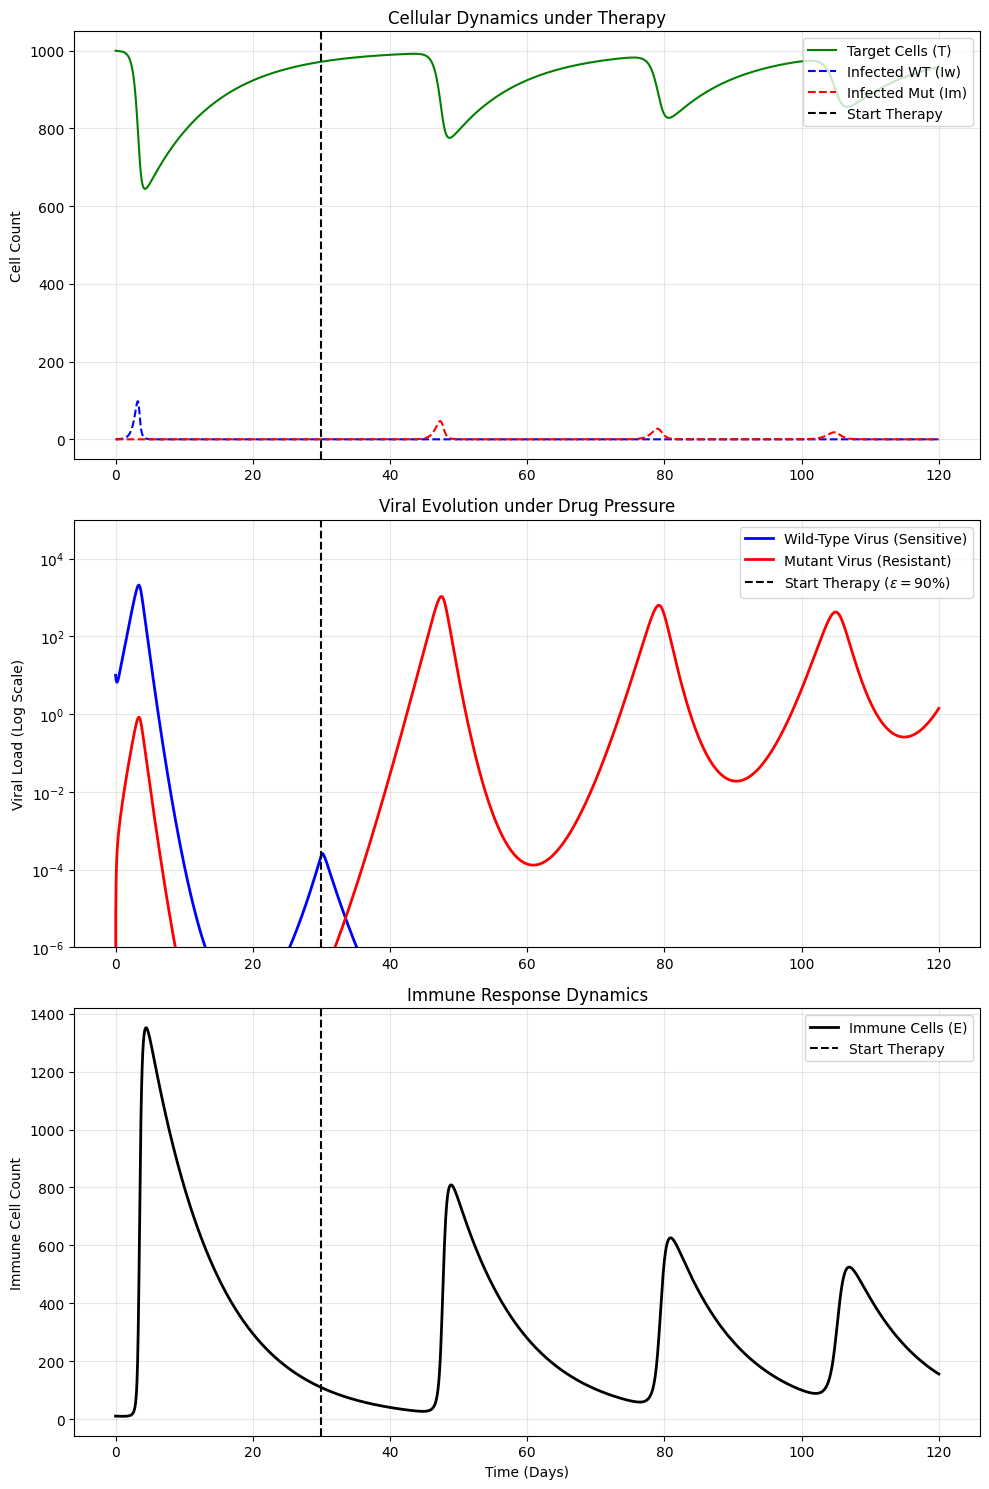

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(10, 15))

ax[0].plot(t_total, sol_total[:, 0], 'g-', linewidth=1.5, label='Target Cells (T)')
ax[0].plot(t_total, sol_total[:, 1], 'b--', linewidth=1.5, label='Infected WT (Iw)')
ax[0].plot(t_total, sol_total[:, 2], 'r--', linewidth=1.5, label='Infected Mut (Im)')

ax[0].axvline(x=30, color='k', linestyle='--', label='Start Therapy')

ax[0].set_ylabel('Cell Count')
ax[0].set_title('Cellular Dynamics under Therapy')
ax[0].legend(loc='upper right')
ax[0].grid(True, alpha=0.3)

ax[1].plot(t_total, sol_total[:, 3], 'b-', linewidth=2, label='Wild-Type Virus (Sensitive)')
ax[1].plot(t_total, sol_total[:, 4], 'r-', linewidth=2, label='Mutant Virus (Resistant)')

ax[1].axvline(x=30, color='k', linestyle='--', label=r'Start Therapy ($\epsilon=90\%$)')

ax[1].set_yscale('log')
ax[1].set_ylim(1e-6, 1e5)
ax[1].set_ylabel('Viral Load (Log Scale)')
ax[1].set_title('Viral Evolution under Drug Pressure')
ax[1].legend(loc='upper right')
ax[1].grid(True, alpha=0.3)

ax[2].plot(t_total, sol_total[:, 5], 'k-', linewidth=2, label='Immune Cells (E)')

ax[2].axvline(x=30, color='k', linestyle='--', label='Start Therapy')

ax[2].set_xlabel('Time (Days)')
ax[2].set_ylabel('Immune Cell Count')
ax[2].set_title('Immune Response Dynamics')
ax[2].legend(loc='upper right')
ax[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

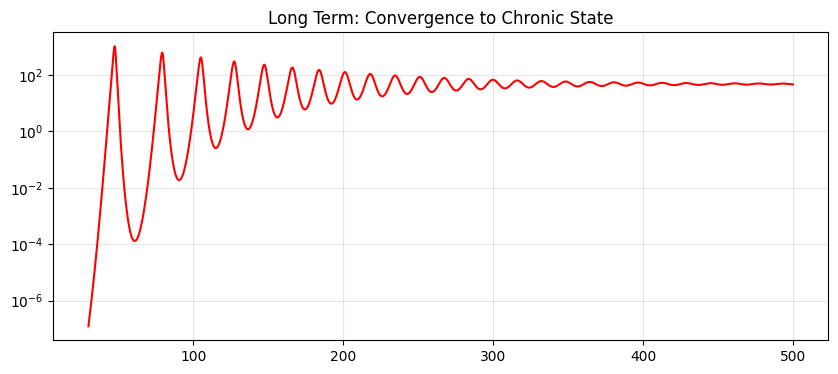

In [9]:
# Phase 2 but with time extended to 500 days
t_long = np.linspace(30, 500, 2000)
sol_long = odeint(ode_system, state_at_30, t_long, args=(params_drug,))

plt.figure(figsize=(10, 4))
plt.plot(t_long, sol_long[:, 4], 'r-', label='Mutant Virus')
plt.title('Long Term: Convergence to Chronic State')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
final_state = sol_long[-1]

final_wt = final_state[3]
final_mut = final_state[4]
final_immune = final_state[5]

print(f"--- FINAL STATUS AT DAY 500 ---")
print(f"Wild-Type Virus (Blue): {final_wt:.10f}")
print(f"Mutant Virus (Red):     {final_mut:.2f} particles")
print(f"Immune Cells:           {final_immune:.2f} cells")

--- FINAL STATUS AT DAY 500 ---
Wild-Type Virus (Blue): -0.0000000000
Mutant Virus (Red):     46.73 particles
Immune Cells:           259.10 cells


<br>

The results demonstrate the phenomenon of **competitive release**:

1. Immediately after therapy begins (dashed line), the wild-type virus (blue) rapidly collapses. The drug reduces its effective reproduction number below one, preventing sustained transmission.

2. As the wild-type population declines, it no longer consumes target cells. This creates an environment rich in available resources which, combined with the absence of drug pressure on the mutant, allows the resistant strain (red) to expand.

3. The resistant mutant, previously suppressed by the wild-type, exploits this opportunity and becomes the dominant strain.

Extending the simulation to longer times reveals the **long-term consequence** of this process.  
By day 500, the oscillations cease and the system reaches a stable chronic state in which the wild-type virus is eliminated, while the mutant viral load stabilizes at approximately 47 particles, controlled by a steady immune population of about 259 cells.


<br>

### <span style="color:#00008B;"> 3.4 &nbsp; Simulating Drug Pressure: Stochastic Response with Gillespie Algorithm</span>  

We run three independent simulations of the infection dynamics under drug treatment, using parameters corresponding to the chronic infection regime. As in the deterministic case, treatment is introduced at day 30 and reduces the infection rate of the wild-type virus, while the resistant mutant is not affected.

Then we compute the mean trajectory across these realizations (after resampling them on a common time grid). This allows us to compare the variability of individual runs with the average trend, and to see how drug pressure can favor the emergence and growth of the resistant mutant.

Running realization 1...
Running realization 2...
Running realization 3...
Running realization 4...
Running realization 5...
Running realization 6...
Running realization 7...
Running realization 8...
Running realization 9...
Running realization 10...
Running realization 11...
Running realization 12...
Running realization 13...
Running realization 14...
Running realization 15...
Running realization 16...
Running realization 17...
Running realization 18...
Running realization 19...
Running realization 20...


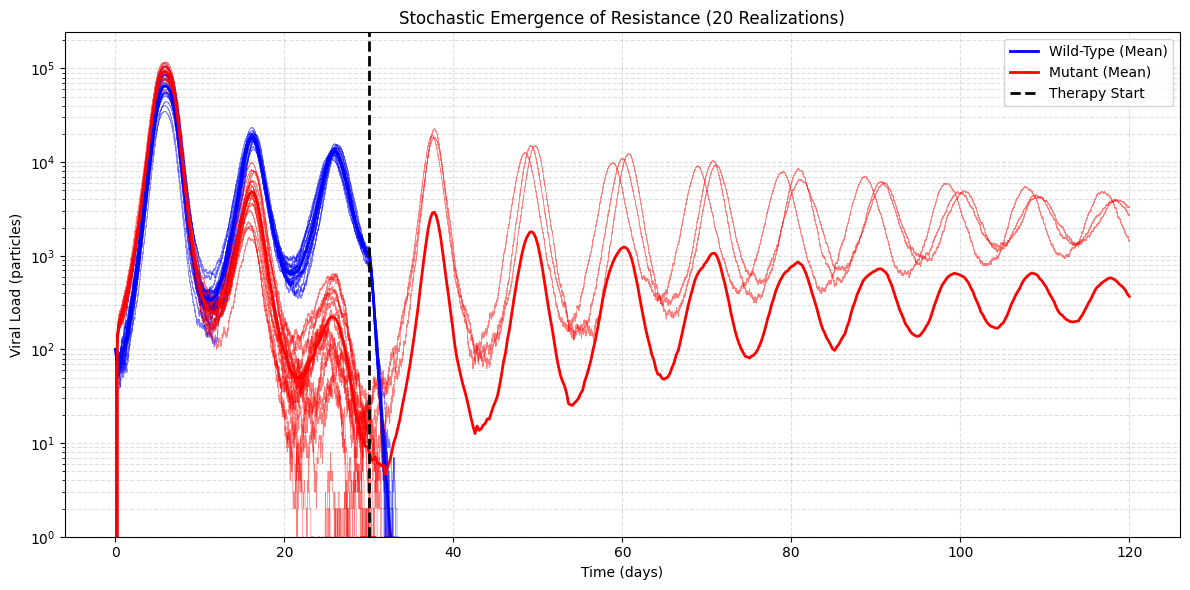

In [11]:
from scipy.interpolate import interp1d
from matplotlib.lines import Line2D

def run_stochastic_therapy_ensemble(params, t_treat, t_end, y0, drug_efficacy, n_realizations):
    all_ts_total = []
    all_ys_total = []

    for _ in range(n_realizations):
        print(f"Running realization {_+1}...")
        # Phase 1: No Drug
        ts1, ys1 = gillespie_ssa(params, t_treat, y0)
        
        state_at_treat = ys1[-1, :].copy()
        
        # Phase 2: With Drug
        params_drug = params.copy()
        params_drug['bw'] = params['bw'] * (1 - drug_efficacy) 
        
        ts2_raw, ys2 = gillespie_ssa(params_drug, t_end - t_treat, state_at_treat)
        ts2 = ts2_raw + t_treat 
        
        ts_total = np.concatenate([ts1, ts2])
        ys_total = np.concatenate([ys1, ys2])
        
        all_ts_total.append(ts_total)
        all_ys_total.append(ys_total)
        
    return all_ts_total, all_ys_total


def resample_trajectories(all_ts, all_ys, common_time_axis):
    n_realizations = len(all_ts)
    n_time_points = len(common_time_axis)
    n_species = all_ys[0].shape[1]
    
    resampled_states = np.zeros((n_realizations, n_time_points, n_species))
    
    for i in range(n_realizations):
        ts = all_ts[i]
        ys = all_ys[i]
        
        _, unique_indices = np.unique(ts, return_index=True)
        ts_unique = ts[unique_indices]
        ys_unique = ys[unique_indices, :]

        if ts_unique[-1] < common_time_axis[-1]:
            extended_ys = np.vstack([ys_unique, np.tile(ys_unique[-1, :], (1, 1))])
            extended_ts = np.concatenate([ts_unique, [common_time_axis[-1]]])
            f_interp = interp1d(extended_ts, extended_ys, axis=0, kind='previous', bounds_error=False, fill_value="extrapolate")
        else:
            f_interp = interp1d(ts_unique, ys_unique, axis=0, kind='previous', bounds_error=False, fill_value="extrapolate")
        
        resampled_states[i, :, :] = f_interp(common_time_axis)
        
    return resampled_states

params_chronic = {
    'lam': 1e4,      
    'dT': 0.01,            
    'bw': 2e-5,
    'bm': 2e-5,
    'pw': 20.0,
    'pm': 18.0,
    'mu': 1e-4,           
    'cw': 4.0,
    'cm': 4.0,
    'delta': 0.5,           
    'k': 1e-4,
    'q': 1e-4,
    'dE': 0.1              
}

y0_therapy = np.array([10000, 10, 50, 100, 0, 10])

t_treatment_start = 30
t_experiment_end = 120
drug_efficacy_beta = 0.90
N_REALIZATIONS = 20

all_ts, all_ys = run_stochastic_therapy_ensemble(
    params_chronic, t_treatment_start, t_experiment_end, y0_therapy, drug_efficacy_beta, N_REALIZATIONS
)

common_time_axis = np.linspace(0, t_experiment_end, 500)
resampled_ys = resample_trajectories(all_ts, all_ys, common_time_axis)

mean_vw = np.mean(resampled_ys[:, :, IDX['Vw']], axis=0)
mean_vm = np.mean(resampled_ys[:, :, IDX['Vm']], axis=0)

fig, ax = plt.subplots(figsize=(12, 6))

for i in range(N_REALIZATIONS):
    ax.plot(all_ts[i], all_ys[i][:, IDX['Vw']], color='blue', linewidth=0.5, alpha=0.5)
    ax.plot(all_ts[i], all_ys[i][:, IDX['Vm']], color='red', linewidth=0.5, alpha=0.5)

ax.plot(common_time_axis, mean_vw, color='blue', linewidth=2, label='Wild-Type (Mean)')
ax.plot(common_time_axis, mean_vm, color='red', linewidth=2, label='Mutant (Mean)')

ax.axvline(t_treatment_start, color='k', linestyle='--', linewidth=2, label='Therapy Start')

ax.set_yscale('log')
ax.set_ylim(bottom=1)
ax.set_xlabel('Time (days)')
ax.set_ylabel('Viral Load (particles)')
ax.set_title(f'Stochastic Emergence of Resistance ({N_REALIZATIONS} Realizations)')

custom_lines = [
    Line2D([0], [0], color='blue', lw=2, label='Wild-Type (Mean)'),
    Line2D([0], [0], color='red', lw=2, label='Mutant (Mean)'),
    Line2D([0], [0], color='k', ls='--', lw=2, label='Therapy Start')
]
ax.legend(handles=custom_lines)
ax.grid(True, which="both", ls="--", alpha=0.4)

plt.tight_layout()
plt.show()

The figure shows 20 independent stochastic realizations of viral dynamics under drug treatment, together with their mean trajectories. Before therapy (day 30), both wild-type and mutant viral loads display oscillatory behavior driven by interactions with the immune response.

After therapy begins (dashed line), the wild-type virus (blue) rapidly declines in all realizations due to the reduced infection rate. In contrast, the resistant mutant (red), which is unaffected by the drug, can sometime increase and become dominant.

Although the overall trend is consistent across realizations, the timing and amplitude of mutant expansion vary due to stochastic effects. The mean trajectories smooth out this variability and highlight the typical outcome: suppression of the wild-type virus followed by sustained growth of the resistant mutant. 

The dominance of the mutant virus post-therapy is determined by the initial conditions at the start of the therapy (day 30). In particular, it heavily depends on the number of infected mutant cells and free mutant viruses, aswell as the number of to-be-infected cells and the strenght of the immune response at that time.

To capture this variability, we compute the survival probability of the mutant virus.

In [12]:
mutant_survival_count = 0
for i in range(N_REALIZATIONS):
    final_state = all_ys[i][-1, :]
    if final_state[IDX['Vm']] > 0 or final_state[IDX['Im']] > 0:
        mutant_survival_count += 1

mutant_survival_probability = (mutant_survival_count / N_REALIZATIONS) * 100

print("\n" + "="*50)
print("MUTANT VIRUS SURVIVAL PROBABILITY")
print("="*50)
print(f"Total Realizations: {N_REALIZATIONS}")
print(f"Mutant Survived:    {mutant_survival_count} times ({mutant_survival_probability:.1f}%)")
print(f"Mutant Extinct:     {N_REALIZATIONS - mutant_survival_count} times ({100 - mutant_survival_probability:.1f}%)")
print("="*50)


MUTANT VIRUS SURVIVAL PROBABILITY
Total Realizations: 20
Mutant Survived:    3 times (15.0%)
Mutant Extinct:     17 times (85.0%)


<br> 

## <span style="color:#00008B;"> 4 &nbsp; Parameter Regime Analysis & Thresholds </span>

To understand why the system behaves as Acute or Chronic, we analyze two biological thresholds derived from the stability analysis of the ODE system.

### <span style="color:#00008B;"> 4.1 &nbsp; The Basic Reproductive Number (R_0) </span>

$R_0$ represents the average number of secondary infected cells produced by a single infected cell introduced into a susceptible population ($T^* = \lambda / d_T$).

From our specific model equations (where virus is consumed during infection), the $R_0$ for the Wild-Type strain is derived as:

$$
R_{0,wt} = \underbrace{\frac{1}{\delta}}_{\text{Lifespan of } I} \times \underbrace{p_w(1-\mu)}_{\text{Virions per } I} \times \underbrace{\frac{\beta_w T^*}{c_w + \beta_w T^*}}_{\text{Prob. virion infects } T}
$$

*   **Regime 1 ($R_0 < 1$):** **Rapid Extinction.** The virus clears naturally; the immune system is not required.
*   **Regime 2 ($R_0 > 1$):** **Establishment.** The virus can grow exponentially.

<br>

### <span style="color:#00008B;"> 4.2 &nbsp; The Immune Activation Threshold </span>

Even if $R_0 > 1$, the infection might be cleared by the immune system (Acute) or persist (Chronic). This depends on whether the immune response can be sustained. From equation $(vi)$, the immune population grows ($\frac{dE}{dt} > 0$) only if the pathogen load exceeds a critical density:

$$
q(I_w + I_m)E > d_E E \implies (I_w + I_m) > \frac{d_E}{q}
$$

*   **Chronic Set Point:** If the viral equilibrium lies above $d_E/q$, the immune system stays active, leading to chronic oscillations or a steady state.
*   **Acute Clearance:** If the immune response pushes the virus below this threshold (and $R_0$ is not massive), the immune population collapses, potentially allowing the virus to rebound (if $R_0 > 1$) or leading to clearance.

<br>

### <span style="color:#00008B;"> 4.3 &nbsp; Drug Resistance Selection Condition </span>

For the mutant to take over during therapy with efficacy $\varepsilon_{\beta}$, we require a "fitness reversal":

$$
R_{0,wt}^{drug} = R_{0,wt} \cdot (1 - \varepsilon_{\beta}) < 1 \quad \text{AND} \quad R_{0,mut} > 1
$$

This creates the **Competitive Release** window where the wild-type dies, freeing up target cells for the resistant mutant to expand.

SCENARIO        | R0 (WT)    | R0 (Mut)   | Immune Thresh (Cells)
-----------------------------------------------------------------
Chronic         | 33.33      | 30.00      | 1000.0              
Acute           | 7.41       | 7.41       | 2.0                 
-----------------------------------------------------------------

Interpretation:
1. If R0 < 1: Extinction is guaranteed (Deterministic).
2. If I_steady_state > Immune Thresh: System supports chronic immune response.


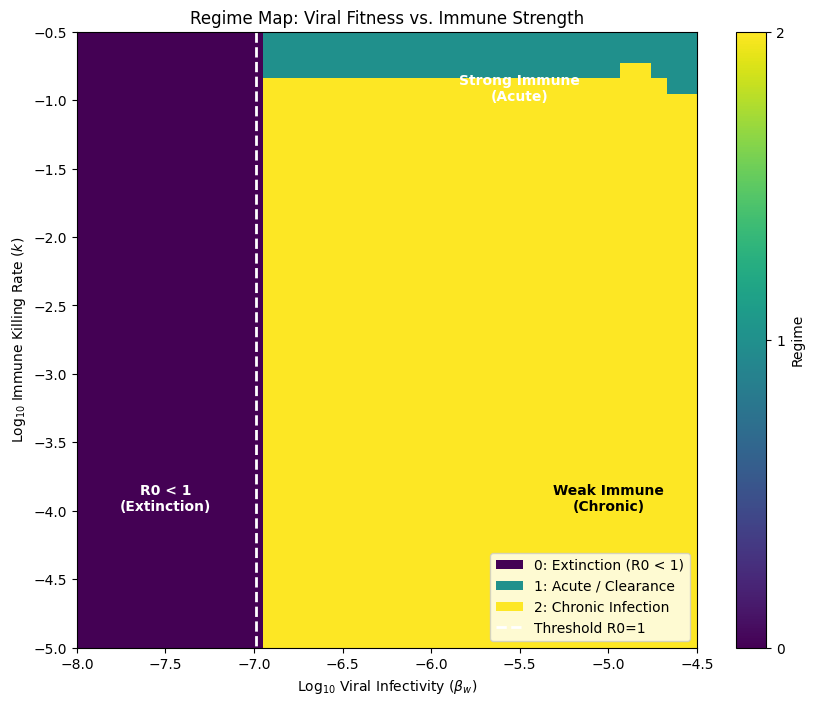

In [13]:
def calculate_thresholds(p):
    T_star = p['lam'] / p['dT']
    
    viral_lifespan_inv = p['cw'] + p['bw'] * T_star
    prob_infection = (p['bw'] * T_star) / viral_lifespan_inv
    r0_wt = (p['pw'] * (1 - p['mu']) / p['delta']) * prob_infection
 
    viral_lifespan_inv_m = p['cm'] + p['bm'] * T_star
    prob_infection_m = (p['bm'] * T_star) / viral_lifespan_inv_m
    r0_mut = (p['pm'] / p['delta']) * prob_infection_m

    i_crit = p['dE'] / p['q']
    
    return r0_wt, r0_mut, i_crit

print(f"{'SCENARIO':<15} | {'R0 (WT)':<10} | {'R0 (Mut)':<10} | {'Immune Thresh (Cells)':<20}")
print("-" * 65)

for name, p_set in [("Chronic", params_chronic), ("Acute", params_acute)]:
    r0_w, r0_m, i_crit = calculate_thresholds(p_set)
    print(f"{name:<15} | {r0_w:<10.2f} | {r0_m:<10.2f} | {i_crit:<20.1f}")

print("-" * 65)
print("\nInterpretation:")
print("1. If R0 < 1: Extinction is guaranteed (Deterministic).")
print("2. If I_steady_state > Immune Thresh: System supports chronic immune response.")

def get_r0(params):
    T_star = params['lam'] / params['dT']
    # Simplified R0 approximation for speed (assuming c >> beta*T)
    # Exact: (p / delta) * (beta * T / (c + beta * T))
    viral_lifespan_inv = params['cw'] + params['bw'] * T_star
    infect_prob = (params['bw'] * T_star) / viral_lifespan_inv
    r0 = (params['pw'] * (1 - params['mu']) / params['delta']) * infect_prob
    return r0

def classify_outcome_robust(params):
    if get_r0(params) < 1.0:
        return 0

    y0_test = [1000, 0, 0, 10, 0, 10] 
    t_eval = np.linspace(0, 1000, 200)
    
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sol = odeint(ode_system, y0_test, t_eval, args=(params,))
    
    V_final = sol[-1, 3] + sol[-1, 4]
    
    if V_final < 1.0:
        return 1
    else:
        return 2

res = 40 
betas = np.logspace(-8, -4.5, res) 
ks = np.logspace(-5, -0.5, res)

phase_grid = np.zeros((res, res))
r0_grid = np.zeros((res, res))

base_params = params_chronic.copy()
base_params['eps_b'] = 0.0

for i, k_val in enumerate(ks):
    for j, b_val in enumerate(betas):
        p_temp = base_params.copy()
        p_temp['k'] = k_val
        p_temp['bw'] = b_val
        
        p_temp['q'] = k_val / 2.0 
        
        phase_grid[i, j] = classify_outcome_robust(p_temp)
        r0_grid[i, j] = get_r0(p_temp)

plt.figure(figsize=(10, 8))

extent = [np.log10(betas[0]), np.log10(betas[-1]), np.log10(ks[0]), np.log10(ks[-1])]
im = plt.imshow(phase_grid, origin='lower', extent=extent, aspect='auto', cmap='viridis')

plt.contour(np.log10(betas), np.log10(ks), r0_grid, levels=[1.0], colors='white', linestyles='dashed', linewidths=2)
plt.text(-7.5, -4, "R0 < 1\n(Extinction)", color='white', ha='center', fontweight='bold')
plt.text(-5.5, -1, "Strong Immune\n(Acute)", color='white', ha='center', fontweight='bold')
plt.text(-5.0, -4, "Weak Immune\n(Chronic)", color='black', ha='center', fontweight='bold')

plt.colorbar(im, ticks=[0, 1, 2], label='Regime')
plt.xlabel(r'Log$_{10}$ Viral Infectivity ($\beta_w$)')
plt.ylabel(r'Log$_{10}$ Immune Killing Rate ($k$)')
plt.title('Regime Map: Viral Fitness vs. Immune Strength')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=plt.cm.viridis(0.0), label='0: Extinction (R0 < 1)'),
    Patch(facecolor=plt.cm.viridis(0.5), label='1: Acute / Clearance'),
    Patch(facecolor=plt.cm.viridis(1.0), label='2: Chronic Infection'),
    Line2D([0], [0], color='white', ls='--', lw=2, label='Threshold R0=1')
]
plt.legend(handles=legend_elements, loc='lower right')

plt.show()

***Interpretation of the Regime Map***

*   **Extinction Zone (Purple):** On the left, the viral infectivity ($\beta$) is too low. The basic reproductive number satisfies $R_0 < 1$, so the infection cannot sustain itself and dies out naturally regardless of the immune response.
*   **Chronic (Yellow):** This yellow region illustrates why chronic infections (like HIV or Hepatitis C) are so difficult to cure. Once the virus crosses the $R_0 > 1$ threshold (the white dashed line), it becomes highly robust. The immune system is active, but it settles into a stalemate with the virus rather than eliminating it.
*   **Clearance Threshold (Teal):** To transition from a Chronic state to total Clearance (Acute), the host needs a massive increase in immune strength (moving vertically up). Only when the killing rate ($k$) and proliferation rate ($q$) become sufficiently high can the immune system overtake viral replication and drive the load to zero.

<br> 

## <span style="color:#00008B;"> 5 &nbsp; Conclusion </span>

In this project, we developed a comprehensive computational framework to study the stochastic evolutionary dynamics of viral infections. By implementing and comparing a deterministic Ordinary Differential Equation (ODE) model with a stochastic Gillespie Simulation Algorithm (SSA), with a focus on the role of randomness in biological systems.

1.  **The Limits of Determinism:** While the ODE model accurately predicts the average behavior of established infections, we demonstrated that it fundamentally fails to capture early-infection dynamics. Our stochastic simulations revealed that even with a Basic Reproductive Number $R_0 > 1$, a small initial viral load faces a significant non-zero probability of **stochastic extinction**.

2.  **Mechanisms of Drug Resistance:** Through the "Competitive Release" experiment, we visualized the evolutionary trade-off inherent in antiviral therapy. We successfully modeled how a drug treatment that suppresses the dominant Wild-Type strain can inadvertently create the perfect environment for a pre-existing, less fit Mutant strain. The stochastic results further showed that this emergence is not inevitable; the "bottleneck" created by the drug treatment can sometimes drive the mutant to extinction before it establishes dominance, a phenomenon invisible to deterministic models.

3.  **Global Parameter Regimes:** By mapping the phase space of Viral Infectivity ($\beta$) versus Immune Strength ($k$), we constructed a regime map that reconciles the mathematical thresholds ($R_0$ and Immune Activation) with biological outcomes. We identified distinct boundaries separating rapid extinction, chronic persistence, and acute immune clearance, providing a global view of how host-pathogen properties dictate disease progression.